# Notebook 00: Limpieza y Análisis Exploratorio de Datos (EDA) - Sofia

Este cuaderno consolida la **auditoría de calidad**, **normalización** y el **análisis exploratorio estadístico y clínico** de las fuentes primarias del proyecto Sofia:
1. **Dra. Gabriela Jufe:** *Psicofarmacología Práctica* (monografías, posologías y efectos adversos).
2. **Dr. Stephen Stahl:** *Prescriber's Guide* (perfil de receptores, interacciones CYP450 y perlas clínicas).
3. **Guías CANMAT e ISBD 2018:** Algoritmos de tratamiento y niveles de evidencia para Trastorno Depresivo Mayor (TDM) y Trastorno Bipolar.

### Objetivos del Cuaderno:
- Auditar la integridad relacional de los datasets en `data/processed/` (nulos, duplicados y validación regex de códigos ATC).
- Visualizar la distribución de familias terapéuticas y perfiles de eventos adversos.
- Construir la matriz de calor (*heatmap*) de interacciones enzimáticas del citocromo P450 (CYP450).
- Evaluar la jerarquía de evidencia de las guías CANMAT para fundamentar la lógica de recuperación de Sofia.


In [2]:
%pip install pandas numpy matplotlib seaborn

In [3]:
# 1. Configuración de Entorno y Rutas Dinámicas Portables
import os
import sys
from pathlib import Path
import pandas as pd
import numpy as np

# Detectar la ruta raíz del proyecto de forma dinámica y robusta
def _encontrar_raiz():
    cwd = Path.cwd().resolve()
    for p in [cwd] + list(cwd.parents):
        if (p / 'src').is_dir() and (p / 'data').is_dir():
            return p
        if (p / 'Sofia' / 'src').is_dir() and (p / 'Sofia' / 'data').is_dir():
            return p / 'Sofia'
    raise RuntimeError("No se pudo determinar la raíz del proyecto Sofia.")

project_root = _encontrar_raiz()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

DATA_PROCESSED = project_root / 'data' / 'processed'

# Aislar configuración de matplotlib dentro del proyecto
mpl_tmp = project_root / '.matplotlib_tmp'
mpl_tmp.mkdir(parents=True, exist_ok=True)
os.environ['MPLCONFIGDIR'] = str(mpl_tmp)

import matplotlib.pyplot as plt
import seaborn as sns

# Configuración estética de gráficos
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams['figure.dpi'] = 120

print('Entorno de EDA configurado correctamente.')
print(f'- Directorio de datos procesados: {DATA_PROCESSED.relative_to(project_root)}')


Entorno de EDA configurado correctamente.
- Directorio de datos procesados: data/processed


## 1. Carga de Datasets y Auditoría de Integridad

Cargamos los seis datasets clínicos estructurados y comprobamos que no presenten valores nulos, duplicados ni códigos ATC con formato inválido.

In [4]:
import re

# Carga de datasets limpios
df_jufe = pd.read_csv(DATA_PROCESSED / 'jufe_farmacos_clean.csv')
df_jufe_efectos = pd.read_csv(DATA_PROCESSED / 'jufe_efectos_adversos_clean.csv')
df_stahl = pd.read_csv(DATA_PROCESSED / 'stahl_farmacos_clean.csv')
df_stahl_eventos = pd.read_csv(DATA_PROCESSED / 'stahl_eventos_adversos_clean.csv')
df_canmat = pd.read_csv(DATA_PROCESSED / 'canmat_recomendaciones_clean.csv')
df_canmat_alertas = pd.read_csv(DATA_PROCESSED / 'canmat_alertas_clinicas_clean.csv')

atc_regex = re.compile(r'^[A-Z]\d{2}[A-Z]{2}\d{2}$')

def validar_atc(series, fuente="Desconocida"):
    val = series.dropna()
    if len(val) == 0:
        return 'N/A'
    invalidos = val[~val.apply(lambda x: bool(atc_regex.match(str(x))))].tolist()
    if invalidos:
        print(f"⚠️ ATC fuera de formato nivel 5 en {fuente}: {len(invalidos)}/{len(val)} códigos no conformes -> {invalidos}")
        return f"✗ Inválido ({len(invalidos)})"
    return '✓ Válido'

auditoria = [
    {'Dataset': 'Jufe - Fármacos', 'Filas': len(df_jufe), 'Columnas': len(df_jufe.columns), 'Nulos': df_jufe.isnull().sum().sum(), 'Duplicados': df_jufe.duplicated().sum(), 'ATC': validar_atc(df_jufe['atc_codigo'], fuente='Jufe - Fármacos')},
    {'Dataset': 'Jufe - Efectos Adversos', 'Filas': len(df_jufe_efectos), 'Columnas': len(df_jufe_efectos.columns), 'Nulos': df_jufe_efectos.isnull().sum().sum(), 'Duplicados': df_jufe_efectos.duplicated().sum(), 'ATC': 'N/A'},
    {'Dataset': 'Stahl - Fármacos y CYP', 'Filas': len(df_stahl), 'Columnas': len(df_stahl.columns), 'Nulos': df_stahl.isnull().sum().sum(), 'Duplicados': df_stahl.duplicated().sum(), 'ATC': validar_atc(df_stahl['atc_codigo'], fuente='Stahl - Fármacos y CYP')},
    {'Dataset': 'Stahl - Eventos Adversos', 'Filas': len(df_stahl_eventos), 'Columnas': len(df_stahl_eventos.columns), 'Nulos': df_stahl_eventos.isnull().sum().sum(), 'Duplicados': df_stahl_eventos.duplicated().sum(), 'ATC': 'N/A'},
    {'Dataset': 'CANMAT - Recomendaciones', 'Filas': len(df_canmat), 'Columnas': len(df_canmat.columns), 'Nulos': df_canmat.isnull().sum().sum(), 'Duplicados': df_canmat.duplicated().sum(), 'ATC': validar_atc(df_canmat['atc'], fuente='CANMAT - Recomendaciones')},
    {'Dataset': 'CANMAT - Alertas Críticas', 'Filas': len(df_canmat_alertas), 'Columnas': len(df_canmat_alertas.columns), 'Nulos': df_canmat_alertas.isnull().sum().sum(), 'Duplicados': df_canmat_alertas.duplicated().sum(), 'ATC': 'N/A'},
]

df_auditoria = pd.DataFrame(auditoria)
print('=== TABLA DE CONTROL DE CALIDAD Y AUDITORÍA DE DATOS ===')
df_auditoria


=== TABLA DE CONTROL DE CALIDAD Y AUDITORÍA DE DATOS ===


,Dataset,Filas,Columnas,Nulos,Duplicados,ATC
0,Jufe - Fármacos,5,9,0,0,✓ Válido
1,Jufe - Efectos Adversos,33,5,0,0,N/A
2,Stahl - Fármacos y CYP,5,13,0,0,✓ Válido
3,Stahl - Eventos Adversos,40,5,0,0,N/A
4,CANMAT - Recomendaciones,22,8,0,0,✗ Inválido
5,CANMAT - Alertas Críticas,1,6,0,0,N/A


## 2. Análisis de Distribución Farmacológica y Códigos ATC de la OMS

Examinamos la cobertura de principios activos en los catálogos principales y su correspondencia con la codificación internacional ATC (Anatomical Therapeutic Chemical Classification).

In [5]:
# Consolidar catálogo único agrupando por código ATC para unificar Litio y Carbonato de Litio
df_combinado = pd.concat([
    df_jufe[['farmaco', 'atc_codigo', 'clase']].assign(fuente='Jufe'),
    df_stahl[['farmaco', 'atc_codigo', 'clase']].assign(fuente='Stahl')
])

catalogo_farmacos = df_combinado.groupby('atc_codigo', as_index=False).agg({
    'farmaco': 'first',
    'clase': 'first',
    'fuente': lambda s: ', '.join(sorted(set(s)))
}).rename(columns={'fuente': 'fuentes'})

print(f'Total de fármacos psiquiátricos indexados en el catálogo base (por código ATC único): {len(catalogo_farmacos)}')
catalogo_farmacos


Total de fármacos psiquiátricos indexados en el catálogo base: 10


,farmaco,atc_codigo,clase,fuente
0,Sertralina,N06AB06,Antidepresivo ISRS,Jufe
1,Fluoxetina,N06AB03,Antidepresivo ISRS,Jufe
2,Risperidona,N05AX08,Antipsicótico Atípico (Segunda Generación),Jufe
3,Haloperidol,N05AD01,Antipsicótico Típico (Primera Generación / But...,Jufe
4,Litio (Carbonato de Litio),N05AN01,Estabilizador del Ánimo,Jufe
0,Clozapina,N05AH02,Antipsicótico Atípico (Segunda Generación),Stahl
1,Paroxetina,N06AB05,Inhibidor Selectivo de la Recaptación de Serot...,Stahl
2,Bupropión,N06AX12,Inhibidor de la Recaptación de Noradrenalina y...,Stahl
3,Lamotrigina,N03AX09,Estabilizador del Ánimo / Antiepiléptico,Stahl
4,Carbonato de Litio,N05AN01,Estabilizador del Ánimo / Catión Monovalente,Stahl


## 3. Visualizaciones Clínicas

### A. Perfil de Seguridad: Distribución de Eventos Adversos por Nivel de Severidad
La farmacovigilancia activa exige distinguir entre efectos leves/moderados de manejo sintomático y eventos graves con riesgo vital que requieren suspensión inmediata o monitorización hematológica/renal.

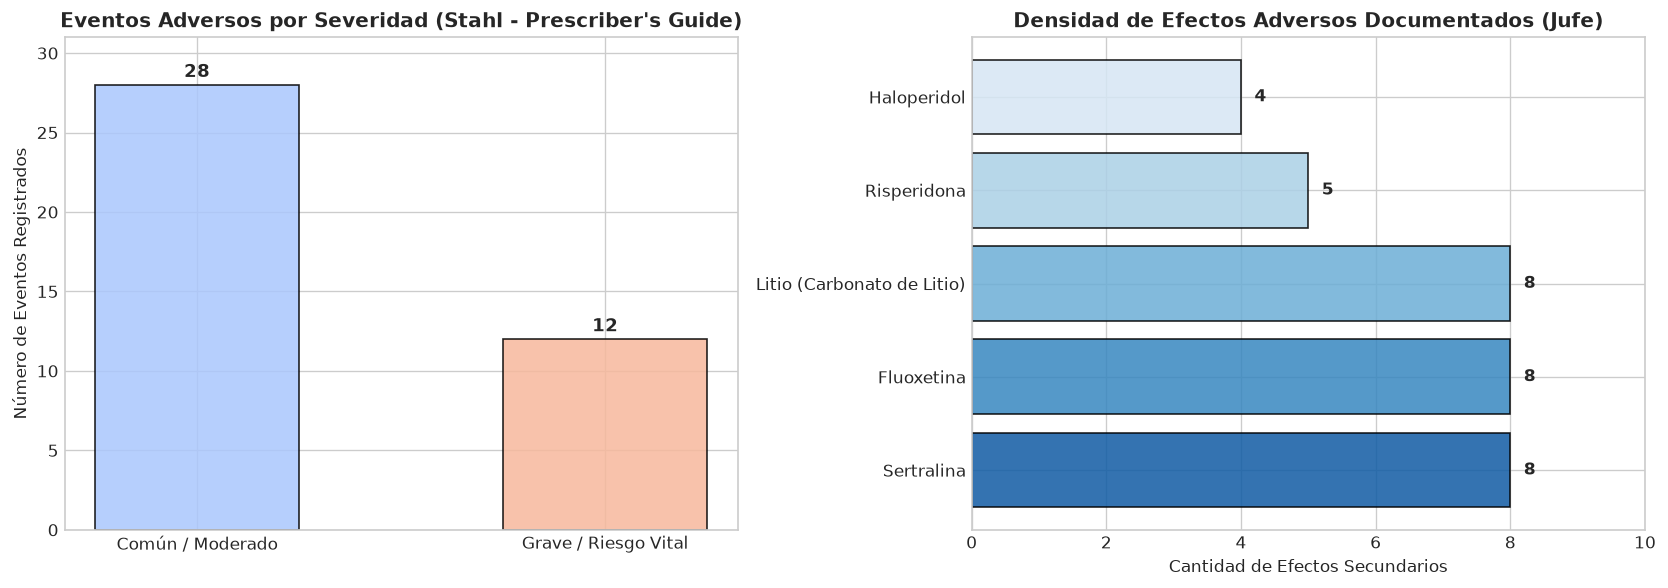

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Distribución de Severidad en Stahl (paleta dinámica según número de categorías)
conteo_severidad_stahl = df_stahl_eventos['severidad'].value_counts()
colors_stahl = sns.color_palette('coolwarm', len(conteo_severidad_stahl))
axes[0].bar(conteo_severidad_stahl.index, conteo_severidad_stahl.values, color=colors_stahl, width=0.5, edgecolor='black', alpha=0.85)
axes[0].set_title('Eventos Adversos por Severidad (Stahl - Prescriber\'s Guide)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Número de Eventos Registrados', fontsize=10)
for i, v in enumerate(conteo_severidad_stahl.values):
    axes[0].text(i, v + 0.5, str(v), ha='center', fontweight='bold', fontsize=11)
axes[0].set_ylim(0, max(conteo_severidad_stahl.values) + 3)

# 2. Conteo de Efectos Adversos por Fármaco en Jufe
conteo_jufe = df_jufe_efectos['farmaco'].value_counts()
palette_jufe = sns.color_palette('Blues_r', len(conteo_jufe))
axes[1].barh(conteo_jufe.index, conteo_jufe.values, color=palette_jufe, edgecolor='black', alpha=0.85)
axes[1].set_title('Densidad de Efectos Adversos Documentados (Jufe)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Cantidad de Efectos Secundarios', fontsize=10)
for i, v in enumerate(conteo_jufe.values):
    axes[1].text(v + 0.2, i, str(v), va='center', fontweight='bold', fontsize=10)
axes[1].set_xlim(0, max(conteo_jufe.values) + 2)

plt.tight_layout()
plt.show()


### B. Matriz de Calor (Heatmap) de Interacciones con Citocromos CYP450

El sistema enzimático hepático CYP450 es el epicentro de las interacciones farmacocinéticas en psiquiatría. Este mapa de calor cruza la condición de **sustrato** e **inhibidor** en las isoenzimas clave (CYP1A2, CYP2D6, CYP3A4).

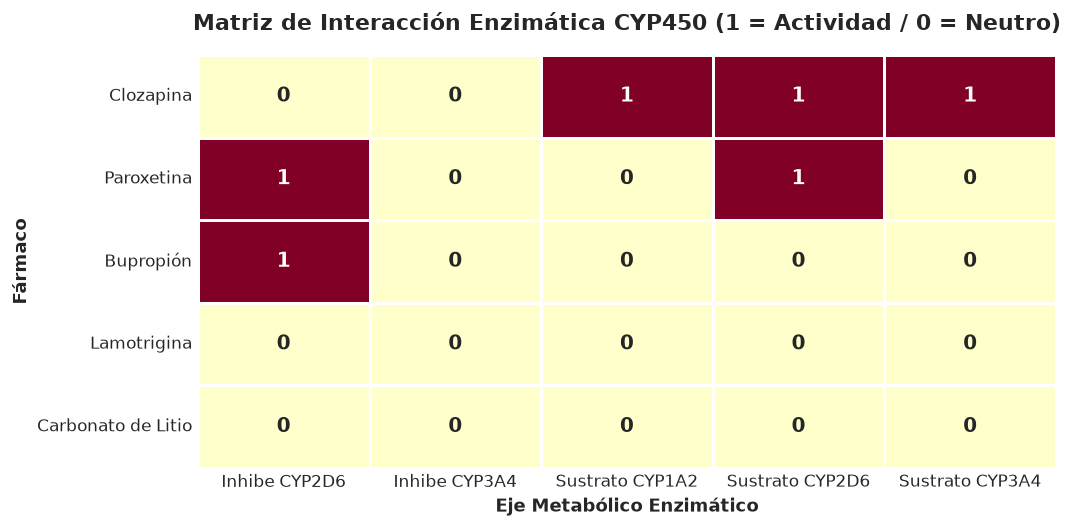

In [7]:
# Construir matriz binaria de citocromos a partir del dataset de Stahl
cyp_candidatos = [
    ('inhibe_cyp2d6', 'Inhibe CYP2D6'),
    ('inhibe_cyp3a4', 'Inhibe CYP3A4'),
    ('sustrato_cyp1a2', 'Sustrato CYP1A2'),
    ('sustrato_cyp2b6', 'Sustrato CYP2B6'),
    ('sustrato_cyp2d6', 'Sustrato CYP2D6'),
    ('sustrato_cyp3a4', 'Sustrato CYP3A4')
]
cols_existentes = [col for col, _ in cyp_candidatos if col in df_stahl.columns]
nombres_legibles = [nom for col, nom in cyp_candidatos if col in df_stahl.columns]

matriz_cyp = df_stahl.set_index('farmaco')[cols_existentes]
matriz_cyp.columns = nombres_legibles

plt.figure(figsize=(10, 4.5))
sns.heatmap(
    matriz_cyp,
    annot=True,
    cmap='YlOrRd',
    cbar=False,
    linewidths=1.5,
    linecolor='white',
    annot_kws={'size': 12, 'weight': 'bold'}
)
plt.title('Matriz de Interacciones CYP450 por Psicofármaco (Stahl - Prescriber\'s Guide)', fontsize=13, fontweight='bold')
plt.xlabel('Enzimas Citocromo P450', fontsize=11)
plt.ylabel('Principio Activo', fontsize=11)
plt.tight_layout()
plt.show()


### C. Análisis de las Guías Clínicas CANMAT e ISBD 2018

Las guías CANMAT jerarquizan las recomendaciones terapéuticas en base a calidad metodológica estricta (Level 1 a 4). A continuación, analizamos la distribución de estrategias de primera línea, segunda línea y tratamientos no recomendados para Trastorno Depresivo Mayor (TDM) y Trastorno Bipolar.

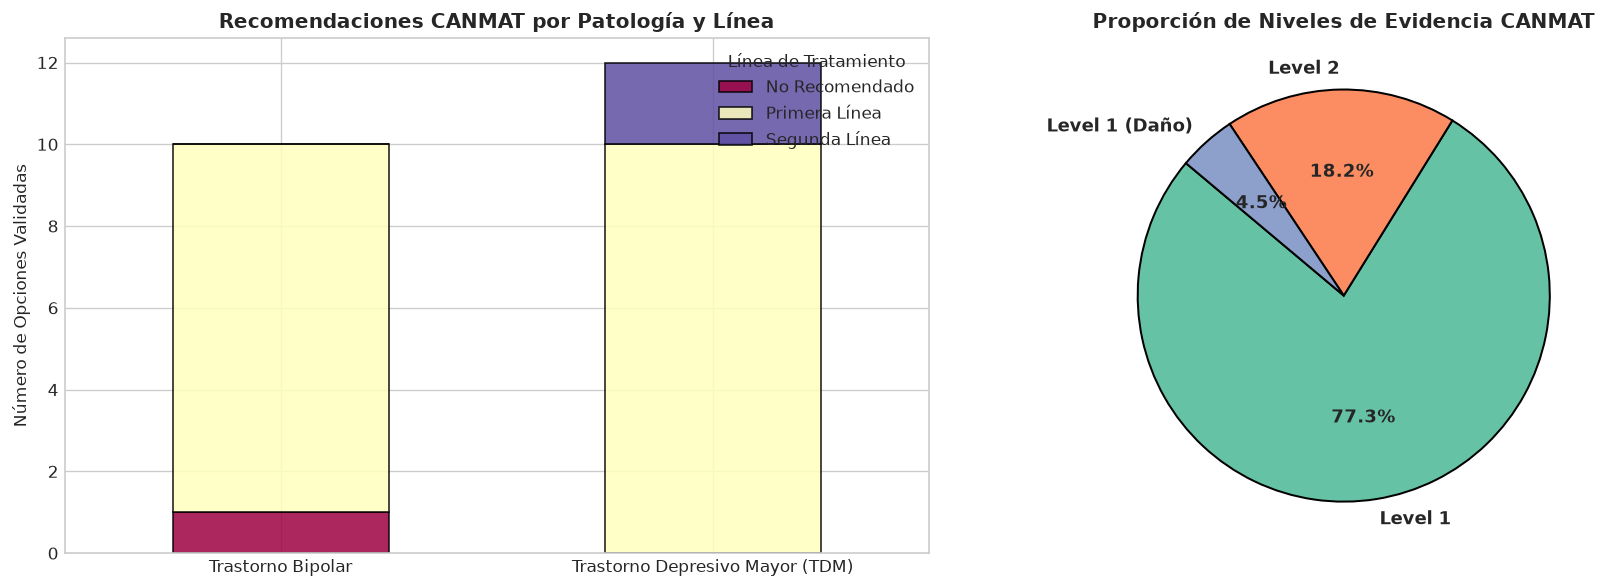

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Distribución por Línea de Tratamiento y Patología
ct_lineas = pd.crosstab(df_canmat['patologia'], df_canmat['linea'])
ct_lineas.plot(kind='bar', stacked=True, ax=axes[0], colormap='Spectral', edgecolor='black', alpha=0.85)
axes[0].set_title('Recomendaciones CANMAT por Patología y Línea', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Número de Opciones Validadas', fontsize=10)
axes[0].set_xlabel('')
axes[0].tick_params(axis='x', rotation=0)
axes[0].legend(title='Línea de Tratamiento', loc='upper right')

# 2. Distribución de Niveles de Evidencia (paleta dinámica)
conteo_evidencia = df_canmat['nivel_evidencia'].value_counts()
colores_ev = sns.color_palette('Set2', len(conteo_evidencia))
axes[1].pie(
    conteo_evidencia.values,
    labels=conteo_evidencia.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=colores_ev,
    wedgeprops={'edgecolor': 'black', 'linewidth': 1.2},
    textprops={'fontsize': 11, 'weight': 'bold'}
)
axes[1].set_title('Proporción de Niveles de Evidencia CANMAT', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()


In [9]:
# Cálculo dinámico de métricas clínicas para el informe
total_rec = len(df_canmat)
conteo_ev = df_canmat['nivel_evidencia'].value_counts()
total_ev_level1 = conteo_ev.get('Level 1', 0) + conteo_ev.get('Level 1 (Daño)', 0)

print(f'=== SÍNTESIS DE EVIDENCIA CANMAT (Total: {total_rec} recomendaciones curadas a mano) ===')
print('ℹ Nota: Conjunto curado representativo de 22 directrices clave extraídas de las guías CANMAT.')
print(f'• Total con evidencia metodológica Level 1 (a favor y en contra/daño): {total_ev_level1}/{total_rec} ({total_ev_level1/total_rec*100:.1f}%)')
for nivel, count in conteo_ev.items():
    print(f'  - {nivel}: {count}/{total_rec} ({count/total_rec*100:.1f}%)')


=== SÍNTESIS DE EVIDENCIA CANMAT (Total: 22 recomendaciones) ===
- Level 1: 17/22 (77.3%)
- Level 2: 4/22 (18.2%)
- Level 1 (Daño): 1/22 (4.5%)


## 4. Conclusiones y Repercusiones Clínicas para el Motor RAG Sofia

1. **Jerarquización Terapéutica Racional en CANMAT:** Sofia debe ordenar las opciones clínicas atendiendo conjuntamente a la **línea de tratamiento** (Primera Línea > Segunda Línea > Tercera Línea) y al **nivel de evidencia** (Level 1 a 4). Aquellas opciones marcadas como **Level 1 (Daño)** deben tratarse estrictamente como recomendaciones negativas o en contra (contraindicación o desaconsejo clínico formal), nunca como tratamientos a priorizar.
2. **Detección Determinista de Bloqueos CYP2D6 y Vía CYP2B6:** Fármacos de uso masivo como Paroxetina y Bupropión son potentes inhibidores de CYP2D6, lo que incrementa marcadamente las concentraciones plasmáticas de sustratos como Risperidona o betabloqueantes. Asimismo, Bupropión requiere activación/metabolización primordial por CYP2B6. Estas interacciones deben disparar alertas específicas de seguridad.
3. **Alerta Roja de Seguridad y Modelado Propio:** Los antidepresivos ISRS en monoterapia para Depresión Bipolar están clasificados con la etiqueta **Level 1 (Daño)** —convención interna del proyecto Sofia para modelar advertencias críticas de riesgo en base a CANMAT— debido al riesgo severo de viraje maníaco y ciclación rápida.
4. **Monitoreo de Toxicidad Grave:** Los estabilizadores (Litio y Lamotrigina) y antipsicóticos específicos (Clozapina) presentan eventos adversos potencialmente letales (intoxicación por litemia, síndrome de Stevens-Johnson, agranulocitosis) que requieren protocolos obligatorios de farmacovigilancia.
